# Spectral analysis: line shapes, baselines, peak fitting and unmixing

This notebook works through a typical UV-Vis / Raman analysis with `specfit`:

1. Gaussian, Lorentzian and Voigt line shapes, and the Voigt width rule,
2. a Beer-Lambert calibration curve,
3. baseline removal by asymmetric least squares,
4. fitting overlapping peaks with uncertainties,
5. unmixing a three-component mixture.

All the spectra here are **synthetic**, generated from known parameters plus noise, so the fitted results can be checked against the truth.

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
import specfit as sf

rng = np.random.default_rng(3)

## 1. Line shapes

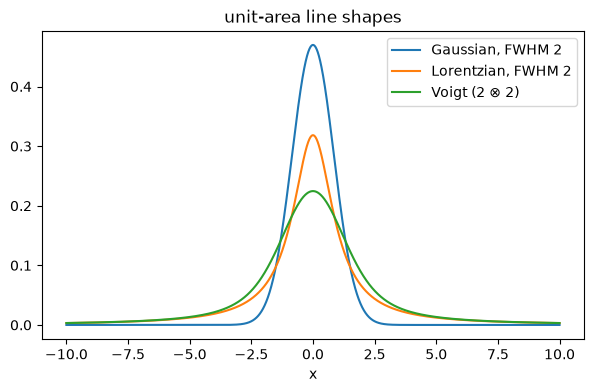

Voigt FWHM  G=1, L=0.2:  measured 1.1110   Olivero 1.1112
Voigt FWHM  G=1, L=1:  measured 1.6376   Olivero 1.6376
Voigt FWHM  G=0.5, L=3:  measured 3.0873   Olivero 3.0868


In [2]:
x = np.linspace(-10, 10, 4001)
plt.figure(figsize=(7, 4))
plt.plot(x, sf.gaussian(x, 0, 2), label="Gaussian, FWHM 2")
plt.plot(x, sf.lorentzian(x, 0, 2), label="Lorentzian, FWHM 2")
plt.plot(x, sf.voigt(x, 0, 2, 2), label="Voigt (2 ⊗ 2)")
plt.legend(); plt.xlabel("x"); plt.title("unit-area line shapes"); plt.show()
for fg, fl in [(1, 0.2), (1, 1), (0.5, 3)]:
    print(f"Voigt FWHM  G={fg}, L={fl}:  measured {sf.measure_fwhm(x, sf.voigt(x, 0, fg, fl)):.4f}   Olivero {sf.voigt_fwhm(fg, fl):.4f}")

## 2. Beer-Lambert calibration

Standards of a dye with ε = 1.5×10⁴ L mol⁻¹ cm⁻¹ in a 1 cm cell, with 0.5 % noise added to the absorbance.

fitted epsilon*l = 14978 (true 15000); intercept -0.0001
unknown with A = 0.42: c = 28.05 umol/L


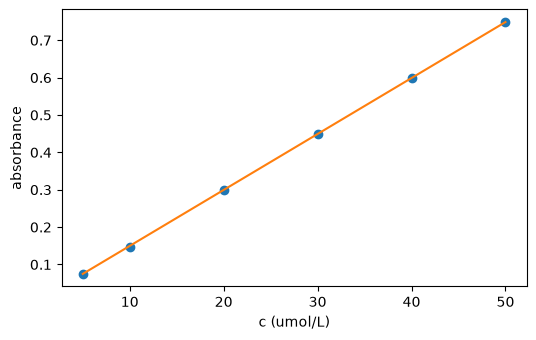

In [3]:
eps = 1.5e4
c_std = np.array([5, 10, 20, 30, 40, 50]) * 1e-6
A_std = eps * c_std * (1 + 0.005 * rng.standard_normal(c_std.size))
slope, intercept = np.polyfit(c_std, A_std, 1)
A_unknown = 0.420
print(f"fitted epsilon*l = {slope:.0f} (true {eps:.0f}); intercept {intercept:.4f}")
print(f"unknown with A = {A_unknown}: c = {(A_unknown - intercept) / slope * 1e6:.2f} umol/L")
plt.figure(figsize=(6, 3.6))
plt.plot(c_std * 1e6, A_std, "o"); plt.plot(c_std * 1e6, slope * c_std + intercept)
plt.xlabel("c (umol/L)"); plt.ylabel("absorbance"); plt.show()

## 3–4. Baseline removal and fitting overlapping peaks

detected peaks at [480.8 539.8 610. ] nm


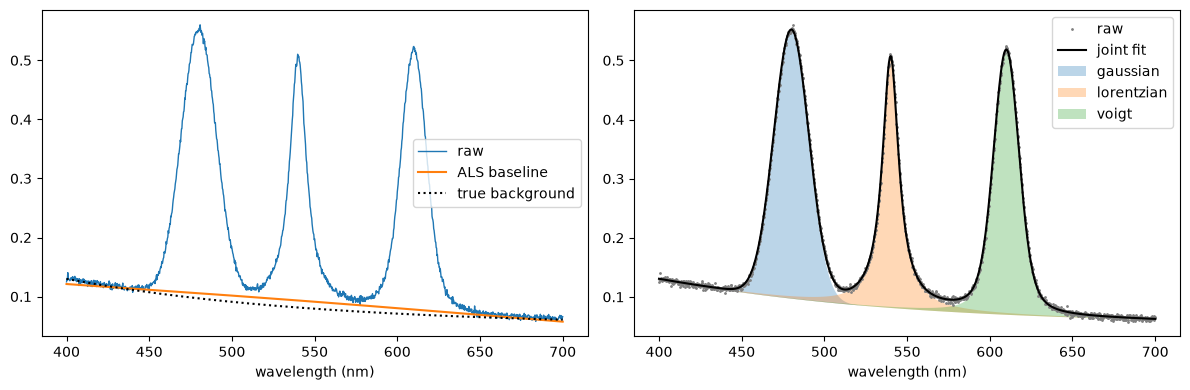

peak         true area    ALS then fit         joint fit
gaussian         12.00    11.617 ± 0.021    12.010 ± 0.020
lorentzian        8.00     7.424 ± 0.022     8.032 ± 0.023
voigt            10.00     9.216 ± 0.042     9.980 ± 0.050


In [4]:
x = np.linspace(400, 700, 1201)
truth = [("gaussian", dict(x0=480.0, area=12.0, fwhm=25.0)),
         ("lorentzian", dict(x0=540.0, area=8.0, fwhm=12.0)),
         ("voigt", dict(x0=610.0, area=10.0, fwhm_g=15.0, fwhm_l=6.0))]
clean = sum(sf.SHAPES[s][0](x, p["x0"], *[p[n] for n in sf.SHAPES[s][1]], area=p["area"]) for s, p in truth)
background = 0.05 + 0.08 * np.exp(-(x - 400) / 150)
y = clean + background + 0.003 * rng.standard_normal(x.size)

base = sf.als_baseline(y, lam=1e9, p=0.001)
corr = y - base
pos, _ = sf.detect_peaks(x, corr)
print("detected peaks at", np.round(pos, 1), "nm")

guesses = [("gaussian", dict(x0=pos[0], area=10, fwhm=20)),
           ("lorentzian", dict(x0=pos[1], area=10, fwhm=20)),
           ("voigt", dict(x0=pos[2], area=10, fwhm_g=10, fwhm_l=10))]
# (a) fit the ALS-corrected spectrum
fit_als = sf.fit_peaks(x, corr, guesses, baseline_order=1)
# (b) fit the raw spectrum, with a cubic baseline fitted together with the peaks
fit_joint = sf.fit_peaks(x, y, guesses, baseline_order=3)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(x, y, lw=1, label="raw"); axes[0].plot(x, base, label="ALS baseline"); axes[0].plot(x, background, "k:", label="true background")
axes[0].legend(); axes[0].set_xlabel("wavelength (nm)")
axes[1].plot(x, y, ".", ms=2, c="gray", label="raw")
axes[1].plot(x, fit_joint.model(x), "k", label="joint fit")
for p in fit_joint.peaks:
    axes[1].fill_between(x, p.evaluate(x) + np.polyval(fit_joint.baseline, x), np.polyval(fit_joint.baseline, x), alpha=0.3, label=p.shape)
axes[1].legend(); axes[1].set_xlabel("wavelength (nm)")
plt.tight_layout(); plt.show()

print(f"{'peak':<12}{'true area':>10}{'ALS then fit':>16}{'joint fit':>18}")
for (s, p), pa, pj, ea, ej in zip(truth, fit_als.peaks, fit_joint.peaks, fit_als.stderr[[1, 4, 7]], fit_joint.stderr[[1, 4, 7]]):
    print(f"{s:<12}{p['area']:>10.2f}{pa.area:>10.3f} ± {ea:.3f}{pj.area:>10.3f} ± {ej:.3f}")

The ALS baseline is quick and needs no model, but it takes part of the broad peak tails, so the areas come out 3–8 % low here. The quoted ± values do not include that bias.
Fitting a smooth baseline together with the peaks removes the bias. This is the better choice whenever the background can be described by a low-order polynomial.

## 5. Unmixing a three-component mixture

true [0.3 1.2 0.5]  recovered [0.301 1.199 0.496]


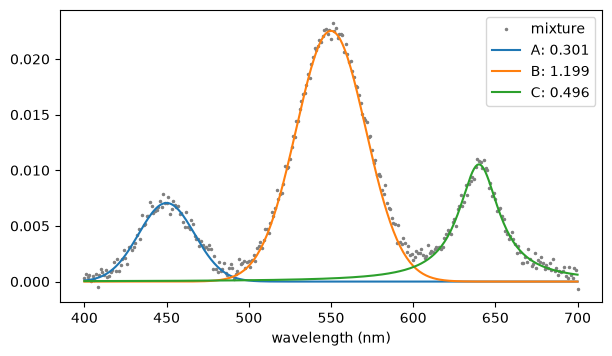

In [5]:
x = np.linspace(400, 700, 301)
refs = np.array([sf.gaussian(x, 450, 40), sf.gaussian(x, 550, 50), sf.lorentzian(x, 640, 30)])
c_true = np.array([0.3, 1.2, 0.5])
mix = c_true @ refs + 0.0005 * rng.standard_normal(x.size)
c, r = sf.unmix(refs, mix)
print("true", c_true, " recovered", np.round(c, 3))
plt.figure(figsize=(7, 3.8))
plt.plot(x, mix, ".", ms=3, c="gray", label="mixture")
for ci, ref, lab in zip(c, refs, ["A", "B", "C"]):
    plt.plot(x, ci * ref, label=f"{lab}: {ci:.3f}")
plt.legend(); plt.xlabel("wavelength (nm)"); plt.show()